### Task 1

In [3]:
!python3 -m pip install --upgrade --quiet google-genai

In [4]:
!gcloud storage cp gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/empty-bowl-on-empty-table.png .
!gcloud storage cp gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/image_editing_utils.py .
!gcloud storage cp gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/place-setting-mask.png .

Copying gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/empty-bowl-on-empty-table.png to file://./empty-bowl-on-empty-table.png
  Completed files 1/1 | 1.4MiB/1.4MiB                                          

Average throughput: 110.7MiB/s
Copying gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/image_editing_utils.py to file://./image_editing_utils.py
  Completed files 1/1 | 5.0kiB/5.0kiB                                          
Copying gs://qwiklabs-gcp-01-3bdde8e7d0ea-bucket/place-setting-mask.png to file://./place-setting-mask.png
  Completed files 1/1 | 4.5kiB/4.5kiB                                          


In [5]:
from google import genai
from google.genai.types import (
    Image,
    EditImageConfig,
    RawReferenceImage,
    MaskReferenceImage,
    MaskReferenceConfig,
)

import image_editing_utils

In [6]:
PROJECT_ID = "qwiklabs-gcp-01-3bdde8e7d0ea"
LOCATION = "us-central1"
gcs_bucket = "qwiklabs-gcp-01-3bdde8e7d0ea-bucket"

client = genai.Client(
    vertexai=True,
    project=PROJECT_ID,
    location=LOCATION
)

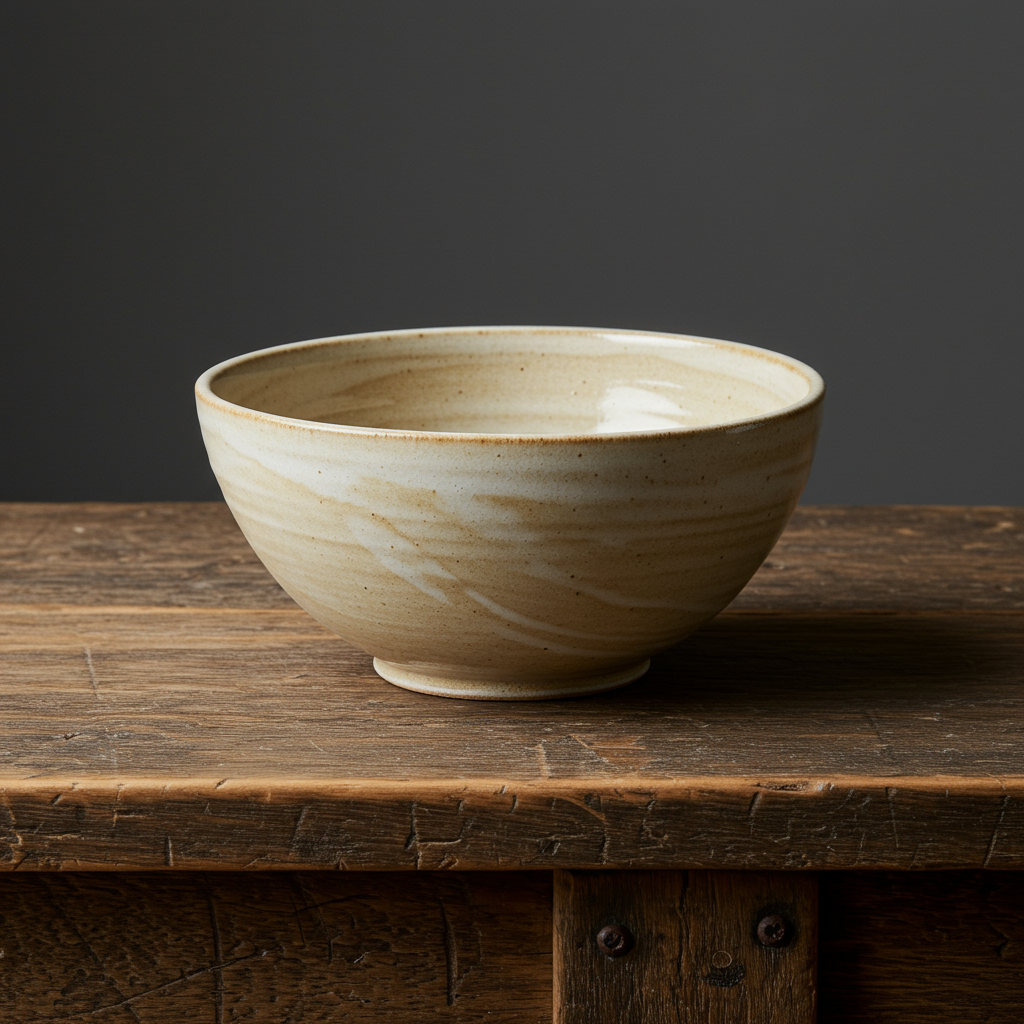

In [7]:
original_image = Image.from_file(
    location="empty-bowl-on-empty-table.png",
    mime_type="image/png"
)
original_image.show()

In [8]:
dest_filename = "empty-bowl-on-empty-table-copy.png"
original_image.save(dest_filename)
image_editing_utils.upload_file_to_gcs(
    gcs_bucket, dest_filename, dest_filename)

File empty-bowl-on-empty-table-copy.png uploaded to empty-bowl-on-empty-table-copy.png.


### Task 2

In [9]:
edit_model_name = "imagen-3.0-capability-001"

In [10]:
target_image_size = (1408, 768)

reframed_image, reframed_mask = image_editing_utils.pad_and_mask_image(
    original_image=original_image,
    target_size=target_image_size,
    vertical_offset_from_bottom=0.5,
    horizontal_offset_from_left=0.1,
)

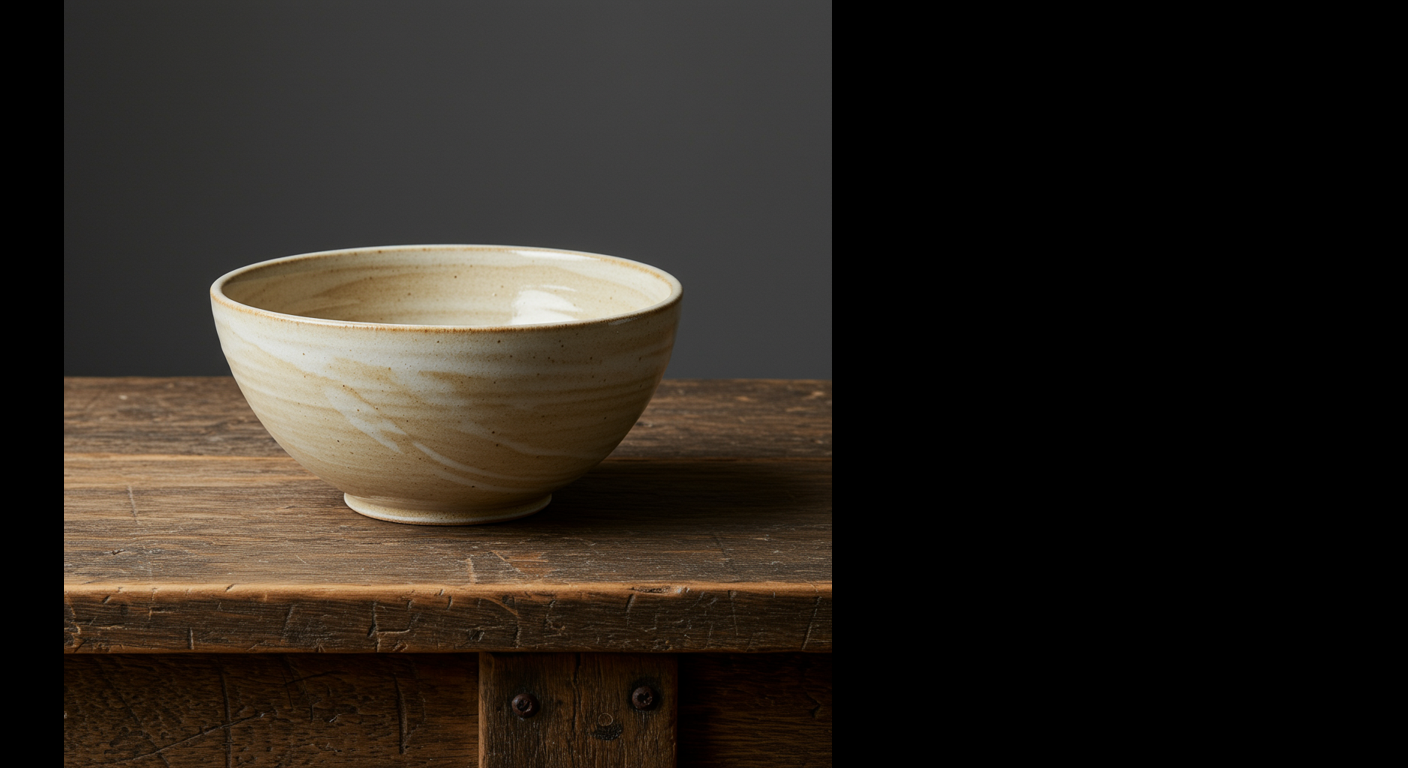

In [11]:
reframed_image.show()

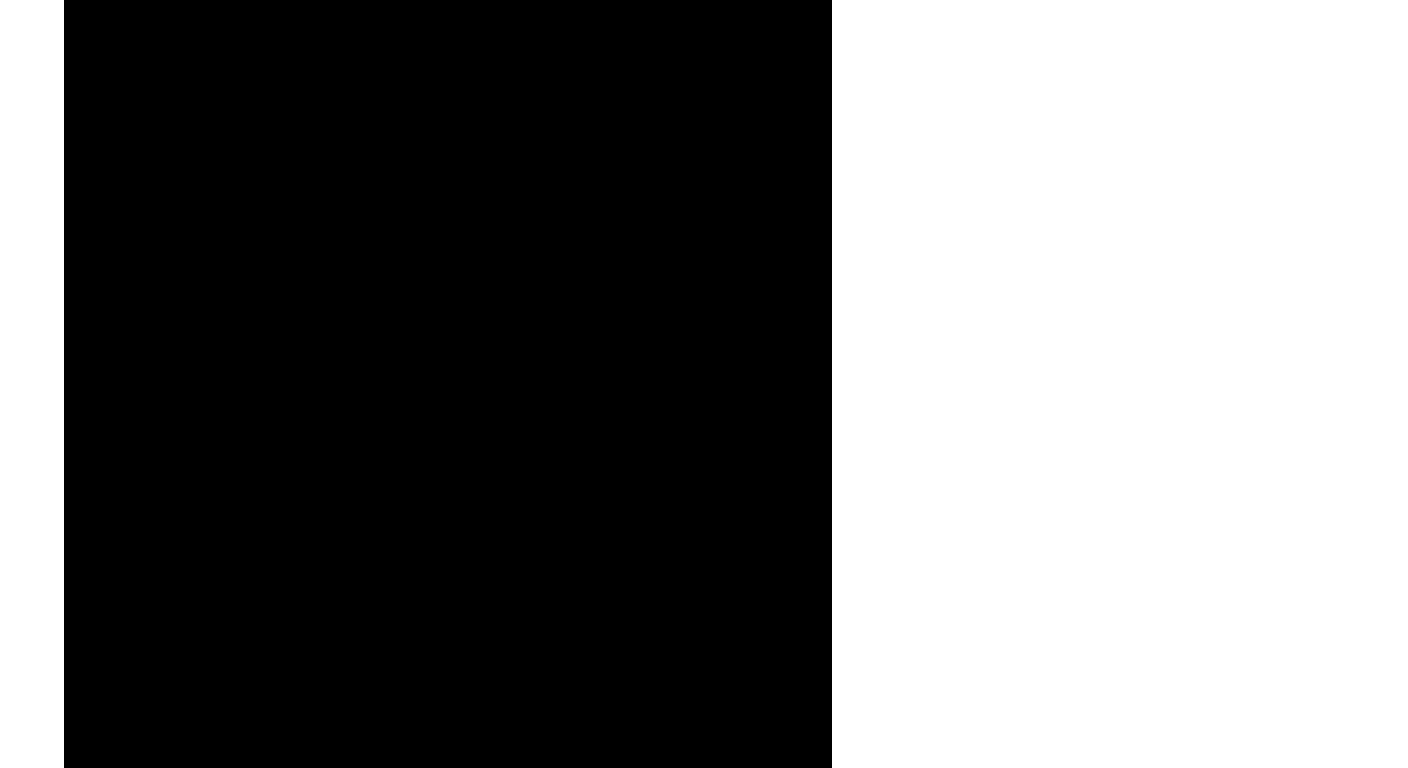

In [12]:
reframed_mask.show()

In [14]:
raw_ref_image = RawReferenceImage(
    # Fill in the appropriate configuration
    reference_image=reframed_image,
    reference_id=0,
)

mask_ref_image = MaskReferenceImage(
    # Fill in the appropriate configuration
    reference_id=1,
    reference_image=reframed_mask,
    config=MaskReferenceConfig(
        mask_mode="MASK_MODE_USER_PROVIDED",
        mask_dilation=0.03,
    ),
)

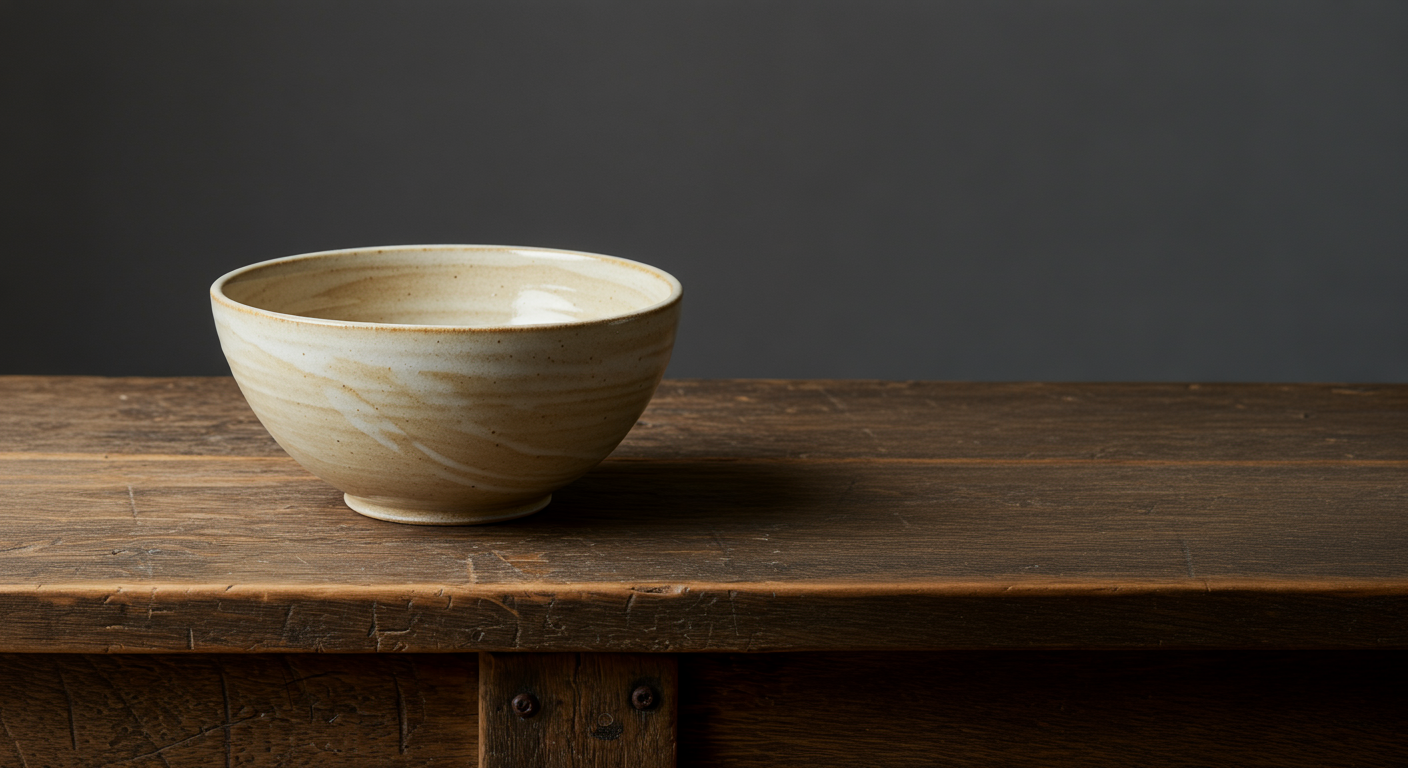

In [15]:
outpainted_image = client.models.edit_image(
    model=edit_model_name,
    prompt="",
    reference_images=[raw_ref_image, mask_ref_image],
    config=EditImageConfig(
        edit_mode= "EDIT_MODE_OUTPAINT",
        number_of_images=1,
        base_steps=35,
        safety_filter_level="BLOCK_ONLY_HIGH",
    ),
)

outpainted_image.generated_images[0].image.show()

In [16]:
filename = "empty-bowl-on-long-table.png"

outpainted_image.generated_images[0].image.save(filename)
image_editing_utils.upload_file_to_gcs(
    gcs_bucket, filename, filename)

File empty-bowl-on-long-table.png uploaded to empty-bowl-on-long-table.png.


### Task 3

In [17]:
raw_ref_image = RawReferenceImage(
    reference_image= outpainted_image.generated_images[0].image, # Reference your outpainted image here,
    reference_id=0
)

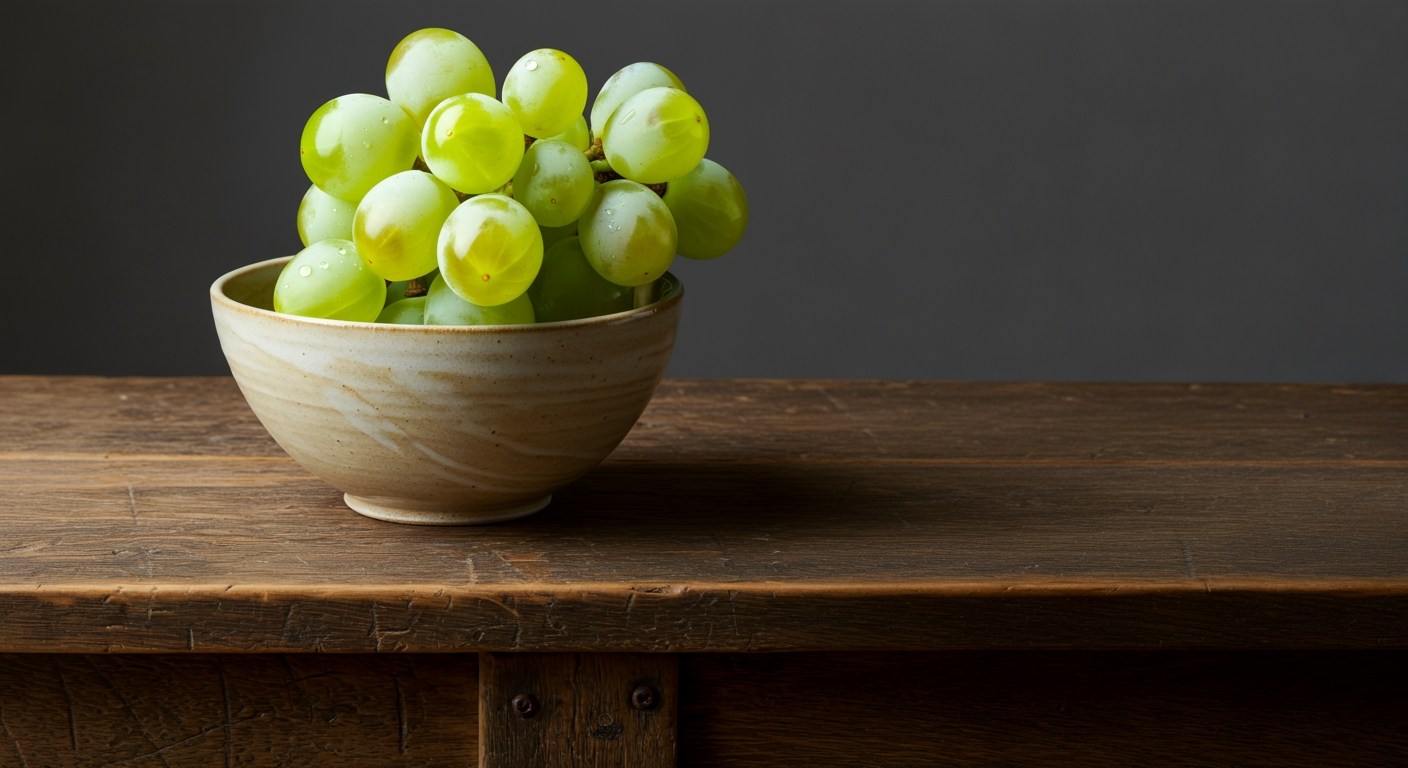

In [19]:
edit_prompt = "photoreal wet grapes added to the ceramic bowl[0]."
edited_image = client.models.edit_image(
    model=edit_model_name,
    prompt=edit_prompt,
    reference_images=[raw_ref_image],
    config=EditImageConfig(
        edit_mode= "EDIT_MODE_DEFAULT" ,
        base_steps=35,
        number_of_images=1,
        safety_filter_level="BLOCK_MEDIUM_AND_ABOVE",
    ),
)

edited_image.generated_images[0].image.show()

In [20]:
filename = "grapes-in-bowl-on-long-table.png"

edited_image.generated_images[0].image.save(filename)
image_editing_utils.upload_file_to_gcs(
    gcs_bucket, filename, filename)

File grapes-in-bowl-on-long-table.png uploaded to grapes-in-bowl-on-long-table.png.


### Task 4

In [23]:
raw_ref_image = RawReferenceImage(
    reference_image= edited_image.generated_images[0].image, # Reference your edited image here,
    reference_id=0
)

In [24]:
place_setting_mask = Image.from_file(location="place-setting-mask.png")
mask_ref_image = MaskReferenceImage(
    # Fill in the appropriate configuration
    reference_id=1,
    reference_image=place_setting_mask,
    config=MaskReferenceConfig(
        mask_mode="MASK_MODE_USER_PROVIDED",
        mask_dilation=0.01,
    ),
)

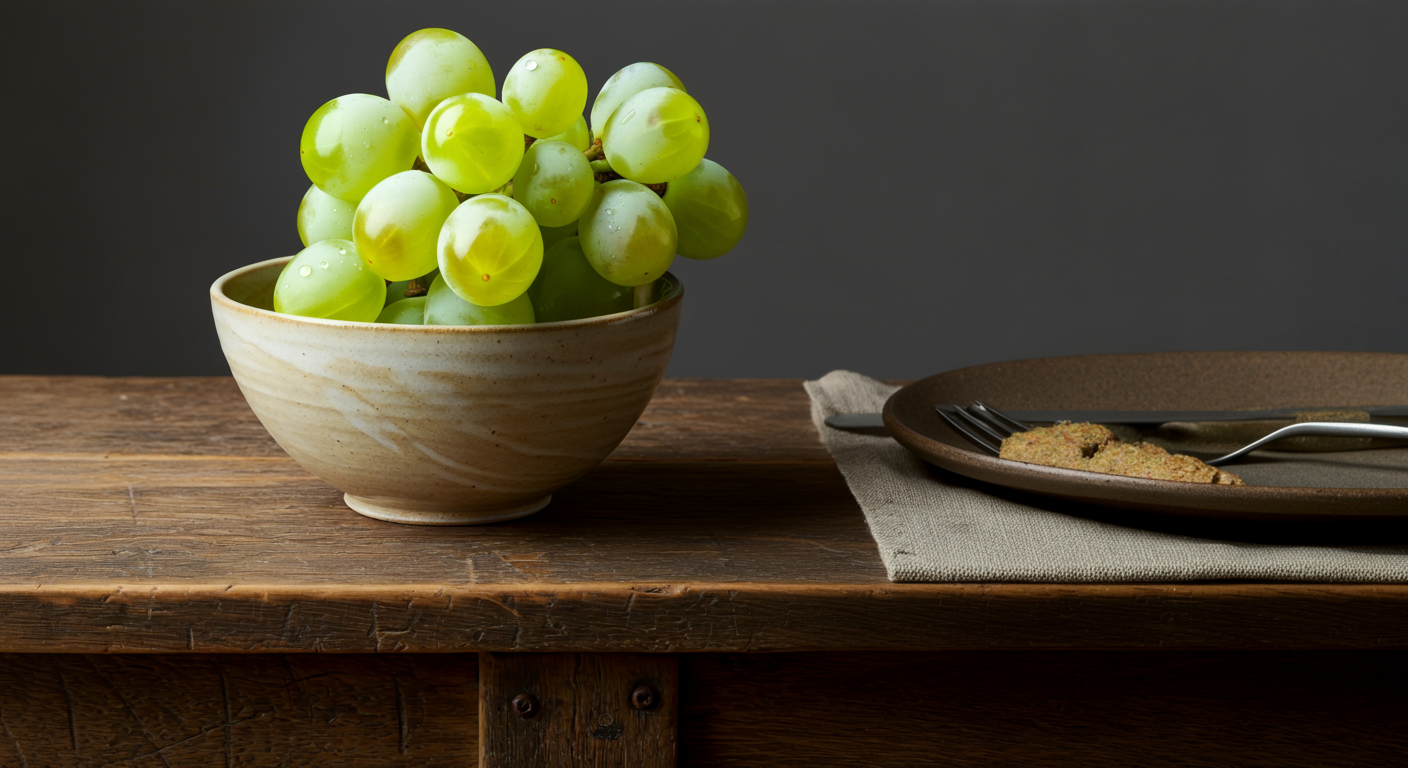

In [25]:
edit_prompt = "a fork on a napkin and a plate on the rustic table[1]"
inpainted_image = client.models.edit_image(
    model=edit_model_name,
    prompt=edit_prompt,
    reference_images=[raw_ref_image, mask_ref_image],
    config=EditImageConfig(
        edit_mode= "EDIT_MODE_INPAINT_INSERTION", #ENTER_THE_CORRECT_EDIT_MODE ,
        number_of_images=1,
        safety_filter_level="BLOCK_MEDIUM_AND_ABOVE",
    ),
)

inpainted_image.generated_images[0].image.show()

In [26]:
filename = "grapes-and-table-setting-on-long-table.png"

inpainted_image.generated_images[0].image.save(filename)
image_editing_utils.upload_file_to_gcs(
    gcs_bucket, filename, filename)

File grapes-and-table-setting-on-long-table.png uploaded to grapes-and-table-setting-on-long-table.png.


### Task 5

In [ ]:
raw_ref_image = RawReferenceImage(
    reference_image= # Reference your inpainted image here,
    reference_id=0
)

In [ ]:
mask_ref_image = MaskReferenceImage(
    # Fill in the appropriate configuration
)

In [ ]:
edit_prompt = ""
foreground_removed_image = client.models.edit_image(
    model=edit_model_name,
    prompt=edit_prompt,
    reference_images=[raw_ref_image, mask_ref_image],
    config=EditImageConfig(
        edit_mode= #ENTER_THE_CORRECT_EDIT_MODE ,
        number_of_images=1,
        safety_filter_level="BLOCK_MEDIUM_AND_ABOVE",
    ),
)

foreground_removed_image.generated_images[0].image.show()

In [ ]:
filename = "empty-table.png"

foreground_removed_image.generated_images[0].image.save(filename)
image_editing_utils.upload_file_to_gcs(
    gcs_bucket, filename, filename)

### Task 6

### Task 7